# Task 6: CNN vs Siamese network, digits and sessions

Both models are compared on the **same split**: train on sessions 1–3, validate on session 4,
test on **session 5** (all 20 writers). Two questions are asked of each model:

1. **Identification:** who wrote this session-5 image (out of 20)?
   - CNN: the class with the highest softmax probability.
   - Siamese: the writer of the nearest *prototype*, the average embedding of each writer × digit
     in sessions 1–3 (prototype idea from Utkin et al.). The digit is not given to either model.
2. **Verification:** are a session-5 image and a session 1–3 image (same digit) by the same writer?
   - Siamese: distance between its embeddings.
   - CNN: distance between its 128-unit penultimate-layer outputs (normalised to length 1). The CNN
     was never trained to compare, so this tests whether its features transfer to the task.
   - Raw pixels: baseline.

The CNN is the augmented model from Task 2. The Siamese network uses the setting chosen on
session 4 in Task 5.

In [1]:
import sys
sys.path.append("../src")
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from scipy.stats import spearmanr

from data_utils import load_handwriting
from siamese import (make_index_table, make_pairs, build_embedding, embed, pair_distance,
                     verification_metrics, prototypes, identify)

images, meta = load_handwriting()
x = images[..., None]
y = meta.person_id.to_numpy()            # writer IDs 1-20
digit = meta.digit.to_numpy()
session = meta.session.to_numpy()
table = make_index_table(meta)
all_writers = np.arange(1, 21)

train_rows = np.where(session <= 3)[0]
val_rows = np.where(session == 4)[0]
test_rows = np.where(session == 5)[0]

I0000 00:00:1792109040.375927    3928 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792109041.547188    3928 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Train the CNN (as in Task 2, with augmentation)

In [2]:
keras.utils.set_random_seed(42)

inp = keras.Input((28, 28, 1))
h = layers.RandomRotation(0.04)(inp)
h = layers.RandomZoom(0.1)(h)
h = layers.RandomTranslation(0.1, 0.1)(h)
h = layers.Conv2D(32, 3, activation="relu")(h)
h = layers.Conv2D(32, 3, activation="relu")(h)
h = layers.MaxPooling2D(2)(h)
h = layers.Dropout(0.25)(h)
h = layers.Conv2D(64, 3, activation="relu")(h)
h = layers.MaxPooling2D(2)(h)
h = layers.Dropout(0.25)(h)
h = layers.Flatten()(h)
features = layers.Dense(128, activation="relu", name="features")(h)
h = layers.Dropout(0.5)(features)
out = layers.Dense(20, activation="softmax")(h)
cnn = keras.Model(inp, out)
cnn.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

cnn.fit(x[train_rows], keras.utils.to_categorical(y[train_rows] - 1, 20),
        validation_data=(x[val_rows], keras.utils.to_categorical(y[val_rows] - 1, 20)),
        epochs=40, batch_size=128, verbose=2,
        callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])

cnn_features = keras.Model(inp, features)          # penultimate layer, for verification

Epoch 1/40


118/118 - 7s - 63ms/step - accuracy: 0.1377 - loss: 2.7400 - val_accuracy: 0.3504 - val_loss: 2.0871


Epoch 2/40


118/118 - 10s - 84ms/step - accuracy: 0.2614 - loss: 2.2456 - val_accuracy: 0.4800 - val_loss: 1.4702


Epoch 3/40


...

118/118 - 6s - 49ms/step - accuracy: 0.5601 - loss: 1.2241 - val_accuracy: 0.5706 - val_loss: 1.1425


Epoch 12/40


118/118 - 5s - 46ms/step - accuracy: 0.5688 - loss: 1.1952 - val_accuracy: 0.5378 - val_loss: 1.3130


Epoch 13/40


118/118 - 6s - 49ms/step - accuracy: 0.5723 - loss: 1.1706 - val_accuracy: 0.5698 - val_loss: 1.2169


## 2. Load the Siamese network chosen in Task 5

In [3]:
hpo = pd.read_csv("../results/siamese_hpo.csv")
best = hpo.sort_values("val AUC", ascending=False).iloc[0]
print("Siamese setting:", dict(best[["margin", "embedding size", "seed"]]))

siamese = build_embedding(dim=int(best["embedding size"]))
siamese.load_weights("../results/siamese_best.weights.h5")
emb_siamese = embed(siamese, x)

f = cnn_features.predict(x, batch_size=1024, verbose=0)
emb_cnn = f / np.maximum(np.linalg.norm(f, axis=1, keepdims=True), 1e-8)

Siamese setting: {'margin': np.float64(0.5), 'embedding size': np.float64(64.0), 'seed': np.float64(1.0)}


## 3. Identification on session 5

In [4]:
probs = cnn.predict(x[test_rows], verbose=0)
cnn_top1 = probs.argmax(axis=1) + 1
cnn_top3 = np.argsort(-probs, axis=1)[:, :3] + 1

proto, proto_writer = prototypes(emb_siamese, meta, train_rows)
sia_top1, sia_top3 = identify(emb_siamese[test_rows], proto, proto_writer)

# The CNN's own features used the same way (nearest prototype), for a like-for-like check
proto_c, proto_writer_c = prototypes(emb_cnn, meta, train_rows)
cnnp_top1, cnnp_top3 = identify(emb_cnn[test_rows], proto_c, proto_writer_c)

truth = y[test_rows]
ident = pd.DataFrame({
    "top-1 accuracy": [(cnn_top1 == truth).mean(), (sia_top1 == truth).mean(),
                       (cnnp_top1 == truth).mean()],
    "top-3 accuracy": [(cnn_top3 == truth[:, None]).any(1).mean(),
                       (sia_top3 == truth[:, None]).any(1).mean(),
                       (cnnp_top3 == truth[:, None]).any(1).mean()],
}, index=["CNN (softmax)", "Siamese (nearest prototype)", "CNN features (nearest prototype)"])
ident.round(3)

,top-1 accuracy,top-3 accuracy
CNN (softmax),0.635,0.905
Siamese (nearest prototype),0.663,0.880
CNN features (nearest prototype),0.707,0.928


## 4. Verification: session-5 image vs session 1–3 image, same digit

In [5]:
i1, i2, label, pair_digit = make_pairs(table, all_writers, 20000, np.random.default_rng(5),
                                       sessions=[5], ref_sessions=[1, 2, 3])
X_flat = images.reshape(len(images), -1)
dists = {"Siamese": pair_distance(emb_siamese, i1, i2),
         "CNN features": pair_distance(emb_cnn, i1, i2),
         "raw pixels": ((X_flat[i1] - X_flat[i2]) ** 2).sum(1)}

# Thresholds chosen on session 4 (validation), applied to session 5
w1, w2, w_label, _ = make_pairs(table, all_writers, 10000, np.random.default_rng(4),
                                sessions=[4], ref_sessions=[1, 2, 3])
val_dists = {"Siamese": pair_distance(emb_siamese, w1, w2),
             "CNN features": pair_distance(emb_cnn, w1, w2),
             "raw pixels": ((X_flat[w1] - X_flat[w2]) ** 2).sum(1)}

ver = {}
for name in dists:
    thr = verification_metrics(val_dists[name], w_label)["threshold"]
    ver[name] = verification_metrics(dists[name], label, thr)
ver = pd.DataFrame(ver).T.drop(columns="threshold")
ver.round(3)

,AUC,EER,false accept,false reject,accuracy
Siamese,0.949,0.121,0.130,0.107,0.881
CNN features,0.932,0.149,0.148,0.150,0.851
raw pixels,0.772,0.278,0.291,0.269,0.720


## 5. Which digits carry more writer information?

In [6]:
test_digit = digit[test_rows]
rows = []
for d in range(5):
    m = test_digit == d
    pm = pair_digit == d
    rows.append({
        "digit": d,
        "CNN identification": (cnn_top1[m] == truth[m]).mean(),
        "Siamese identification": (sia_top1[m] == truth[m]).mean(),
        "Siamese verification AUC": verification_metrics(dists["Siamese"][pm], label[pm])["AUC"],
        "CNN-feature verification AUC": verification_metrics(dists["CNN features"][pm], label[pm])["AUC"],
    })
by_digit = pd.DataFrame(rows).set_index("digit")

# Unseen writers (Task 3, writer-disjoint folds)
folds = pd.read_csv("../results/siamese_writer_folds_by_digit.csv")
by_digit["Siamese AUC, unseen writers (mean of 5 folds)"] = folds.groupby("digit").AUC.mean()
print(by_digit.round(3))
print("\nRank of each digit (1 = most writer information):")
print(by_digit.rank(ascending=False).astype(int))

       CNN identification  Siamese identification  Siamese verification AUC  \
digit                                                                         
0                   0.702                   0.684                     0.951   
1                   0.513                   0.630                     0.939   
2                   0.673                   0.649                     0.948   
3                   0.666                   0.601                     0.958   
4                   0.623                   0.750                     0.953   

       CNN-feature verification AUC  \
digit                                 
0                             0.935   
1                             0.915   
2                             0.942   
3                             0.934   
4                             0.947   

       Siamese AUC, unseen writers (mean of 5 folds)  
digit                                                 
0                                              0.879  
1      

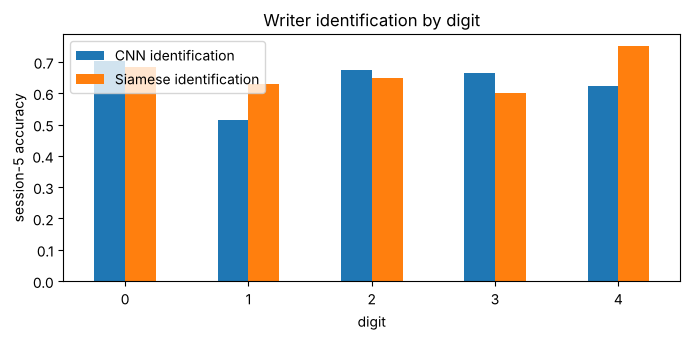

In [7]:
ax = by_digit[["CNN identification", "Siamese identification"]].plot.bar(figsize=(7, 3.5), rot=0)
ax.set_ylabel("session-5 accuracy")
ax.set_title("Writer identification by digit")
plt.tight_layout()
plt.show()

A rough check on noise: with 1,000 session-5 images per digit, an accuracy of about 0.6 has a
binomial standard error of about 0.015, and Task 2 showed that retraining can reorder the
digits. Treat a digit as carrying more writer information only if it ranks high consistently
across the columns above.

## 6. How do session changes affect performance?

In [8]:
# (a) Same-session vs different-session pairs for unseen writers (Task 3)
folds_all = pd.read_csv("../results/siamese_writer_folds.csv")
print("Siamese, unseen writers (mean over 5 folds):")
print(folds_all[folds_all.model == "Siamese"].groupby("pairs")[["AUC", "EER"]].mean().round(3))

# (b) Identification on the validation session (4) vs test session (5)
for name, s in [("session 4", val_rows), ("session 5", test_rows)]:
    c = (cnn.predict(x[s], verbose=0).argmax(1) + 1 == y[s]).mean()
    t1, _ = identify(emb_siamese[s], proto, proto_writer)
    print(f"{name}: CNN {c:.3f} | Siamese {(t1 == y[s]).mean():.3f}")

Siamese, unseen writers (mean over 5 folds):
                AUC    EER
pairs                     
diff_digit    0.752  0.312
diff_session  0.876  0.199
same_session  0.997  0.023


session 4: CNN 0.592 | Siamese 0.627


session 5: CNN 0.635 | Siamese 0.663


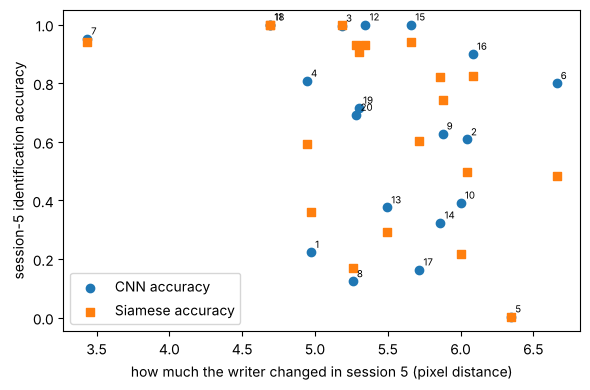

Spearman correlation, shift vs CNN accuracy: -0.39 (p = 0.086, 20 writers)
Spearman correlation, shift vs Siamese accuracy: -0.52 (p = 0.019, 20 writers)


,session shift,CNN accuracy,Siamese accuracy
writer,,,
7,3.434,0.952,0.940
11,4.692,1.000,1.000
18,4.693,1.000,1.000
4,4.944,0.808,0.592
1,4.973,0.224,0.360
3,5.185,0.996,1.000
8,5.259,0.124,0.168
20,5.285,0.692,0.932
19,5.302,0.716,0.908


In [9]:
# (c) Per writer: does a bigger change between sessions mean lower accuracy?
# Session shift = distance between the writer's average session-5 image and average
# session 1-3 image, averaged over the five digits.
shift = []
for w in all_writers:
    d_list = []
    for d in range(5):
        new = X_flat[(y == w) & (digit == d) & (session == 5)].mean(0)
        old = X_flat[(y == w) & (digit == d) & (session <= 3)].mean(0)
        d_list.append(np.linalg.norm(new - old))
    shift.append(np.mean(d_list))

per_writer = pd.DataFrame({
    "session shift": shift,
    "CNN accuracy": pd.Series(cnn_top1 == truth).groupby(truth).mean().values,
    "Siamese accuracy": pd.Series(sia_top1 == truth).groupby(truth).mean().values,
}, index=pd.Index(all_writers, name="writer"))

fig, ax = plt.subplots(figsize=(6, 4))
for col, marker in [("CNN accuracy", "o"), ("Siamese accuracy", "s")]:
    ax.scatter(per_writer["session shift"], per_writer[col], marker=marker, label=col)
for w, r in per_writer.iterrows():
    ax.annotate(str(w), (r["session shift"], r["CNN accuracy"]), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("how much the writer changed in session 5 (pixel distance)")
ax.set_ylabel("session-5 identification accuracy")
ax.legend()
plt.tight_layout()
plt.show()

for col in ["CNN accuracy", "Siamese accuracy"]:
    rho, p = spearmanr(per_writer["session shift"], per_writer[col])
    print(f"Spearman correlation, shift vs {col}: {rho:.2f} (p = {p:.3f}, 20 writers)")
per_writer.round(3).sort_values("session shift")

## Notes for the report (in your own words)

- **Which model for which job:** compare the CNN and Siamese on identification (section 3) and
  verification (section 4). The CNN is built for the closed set of 20 writers. The Siamese
  network also works for writers it has never seen (Task 3), and needs only a few reference
  images to enrol a new writer, with no retraining.
- **Do the CNN's features transfer?** Compare "CNN features" with "Siamese" in section 4.
- **Digits:** use the rank table and the noise check. Only claim a digit is more informative if
  it ranks high consistently. Link to the EDA (e.g. which digits vary most between writers in
  slant and width).
- **Sessions:** the same-session vs different-session gap, and the per-writer relation between
  session shift and accuracy, show how much a new session costs and who suffers most.